# Lucrare de laborator nr. 6: RAG pe un set propriu de documente

**Student:** Daniel Pănuța, grupa IASD 2501 · **Disciplina:** Inteligența artificială generativă · **Profesor:** V. Ursachi

**Obiectiv:** construiesc un sistem **RAG** (*Retrieval-Augmented Generation*) care răspunde la întrebări despre **Regulamentul USM cu privire la organizarea și desfășurarea studiilor superioare de master (ciclul II)**, 13 pagini, 94 de puncte. Compar mai multe metode de căutare și evaluez cu date atât căutarea, cât și răspunsurile.

**De ce e nevoie de RAG.** Un model de limbaj știe doar ce a văzut la antrenare. Regulamentul intern al USM aproape sigur nu e printre acele date. Întrebat direct, modelul fie spune ceva general, fie **inventează** (halucinează) cifre și reguli. RAG rezolvă asta în doi pași:

1. **caută** în documente fragmentele relevante pentru întrebare;
2. îi dă modelului fragmentele ca **context** și îi cere să răspundă **doar** din ele, cu **citarea sursei** (pagina).

Așa răspunsul se poate verifica, iar documentul se poate actualiza fără reantrenarea modelului.

**Pipeline-ul:**

```
PDF ──► ingestie (text pe pagini, curățare, diacritice)
    ──► fragmentare (lungime fixă / pe puncte)
    ──► indexare (BM25 lexical + embeddings dense)
    ──► căutare (BM25 | dens | hibrid RRF | hibrid + reranker)
    ──► generare (Qwen2.5-3B-Instruct, cu citare [p. N])
    ──► evaluare (Hit@k, MRR pentru căutare; corectitudine, fidelitate, citare pentru răspunsuri)
```

**Pașii lucrării:**

1. Ingestia documentului.
2. Fragmentarea, cu două strategii.
3. Indexarea: lexicală și densă.
4. Căutarea: patru variante.
5. Setul de evaluare: 20 de întrebări, cu răspunsul de referință și punctul sursă.
6. Evaluarea căutării.
7. Generarea, plus comparația cu modelul fără RAG.
8. Evaluarea răspunsurilor.
9. Experimentul: dimensiunea fragmentelor și numărul de fragmente $k$.
10. Concluzii și raport.

## 0. Mediul de lucru

Notebook-ul e rulat pe **Google Colab, GPU T4**. Modelul generator Qwen2.5-3B (~6 GB în float16) nu încape confortabil în cei 8 GB ai Mac-ului meu, alături de restul. Celula de mai jos instalează pe Colab bibliotecile lipsă; local nu face nimic.

**Modelele folosite** (toate deschise, fără cheie API):

| Rol | Model | De ce |
|---|---|---|
| Embeddings (căutare densă) | `intfloat/multilingual-e5-small` | multilingv (inclusiv româna), mic (118 M parametri), antrenat pentru căutare |
| Reranker | `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` | cross-encoder multilingv, antrenat pe MS MARCO tradus |
| Generator | `Qwen/Qwen2.5-3B-Instruct` | model de instrucțiuni care scrie bine în română; încape pe T4 |

Generatorul se poate schimba prin variabila de mediu `LAB6_LLM`. Eu am folosit-o la testele locale cu `Qwen/Qwen2.5-0.5B-Instruct`. Rezultatele de mai jos sunt cu modelul de 3B.

In [1]:
# Doar pe Colab: bibliotecile care nu sunt preinstalate
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf", "rank_bm25", "sentence-transformers", "transformers<5"], check=True)

In [2]:
import os, re, json, time, random, unicodedata, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pymupdf
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM
import transformers, sentence_transformers

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
LLM_NAME = os.environ.get("LAB6_LLM", "Qwen/Qwen2.5-3B-Instruct")
EMB_NAME = "intfloat/multilingual-e5-small"
RERANK_NAME = "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"

print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | sentence-transformers {sentence_transformers.__version__} | PyMuPDF {pymupdf.__version__}")
print("Dispozitiv:", device, "| generator:", LLM_NAME)
os.makedirs("data", exist_ok=True); os.makedirs("artifacts", exist_ok=True)

PyTorch 2.11.0+cu130 | transformers 4.57.6 | sentence-transformers 5.7.0 | PyMuPDF 2.1
Dispozitiv: cuda | generator: Qwen/Qwen2.5-3B-Instruct


## 1. Ingestia documentului

**Documentul:** Regulamentul USM pentru studiile de master, PDF public de pe usm.md. Dacă nu există local în `data/`, celula îl descarcă.

**Extragerea textului:** folosesc PyMuPDF. Am încercat întâi `pypdf`, dar acesta strica diacriticele: „profesional ă”, „licen ță”, cu spațiu înaintea literei cu diacritic. Asemenea erori ar fi rupt cuvintele în căutare. PyMuPDF extrage textul curat.

**Curățarea:**

- **Antetul paginii** (numărul paginii, pe primul rând) îl scot.
- **Marcajele de listă** (caracterul privat ``) le înlocuiesc cu „•”.
- **Diacriticele cu sedilă** (ş, ţ) le transform în **diacritice cu virgulă** (ș, ț), forma corectă în română. Altfel „şi” și „și” ar fi cuvinte diferite pentru BM25 și pentru embeddings. Numărăm câte înlocuiri s-au făcut.

Păstrez textul **rând cu rând**, cu pagina fiecărui rând, ca să pot găsi apoi punctele regulamentului („1.”, „2.”, …) la început de rând.

In [3]:
PDF_PATH = "data/Regulament_master_USM.pdf"
PDF_URL = ("https://usm.md/wp-content/uploads/Anexa-2.1.18.-Regulament-de-organizare-si-desfasurare-"
           "a-studiilor-superioare-de-master-ciclul-II.pdf")
if not os.path.exists(PDF_PATH):
    urllib.request.urlretrieve(PDF_URL, PDF_PATH)

SEDILA = str.maketrans({"ş": "ș", "ţ": "ț", "Ş": "Ș", "Ţ": "Ț"})

def curata_pagina(text):
    lines = text.split("\n")
    if lines and lines[0].strip().isdigit():           # antetul cu numărul paginii
        lines = lines[1:]
    return "\n".join(l.replace("", "•").rstrip() for l in lines)

doc = pymupdf.open(PDF_PATH)
raw_pages = [p.get_text() for p in doc]
n_sedila = sum(sum(t.count(c) for c in "şţŞŢ") for t in raw_pages)
pages = [curata_pagina(t).translate(SEDILA) for t in raw_pages]

# textul complet + pagina fiecărui caracter (prin offset-ul de început al fiecărei pagini)
full_text, page_start = "", []
for i, t in enumerate(pages, 1):
    page_start.append(len(full_text)); full_text += t + "\n"
page_start = np.array(page_start)
def page_of(offset):
    return int(np.searchsorted(page_start, offset, side="right"))   # paginile încep de la 1

stats = pd.DataFrame({"pagina": range(1, len(pages) + 1),
                      "caractere": [len(t) for t in pages],
                      "cuvinte": [len(t.split()) for t in pages]})
print(f"Pagini: {len(pages)} | caractere: {stats.caractere.sum()} | cuvinte: {stats.cuvinte.sum()}")
print(f"Diacritice cu sedilă înlocuite: {n_sedila} | ș/ț cu virgulă în text: {full_text.count('ș') + full_text.count('ț')}")
print("\nÎnceputul paginii 6:\n" + pages[5][:600])
stats.T

Pagini: 13 | caractere: 34682 | cuvinte: 4964
Diacritice cu sedilă înlocuite: 0 | ș/ț cu virgulă în text: 610

Începutul paginii 6:
suplimentar - 30 credite de studii ECTS, organizat preliminar (cu taxă de studii), comparativ
cu programele de master oferite absolvenților aceluiași domeniu de formare profesională.

33. Persoanele care nu au acumulat în perioada stabilită minimumul curricular de 30 de credite de
studii transferabile, își pierd calitatea de student și sunt exmatriculați.

34. Metodologia de acumulare a minimului curricular inițial, implicit forma de evaluare la
finalizarea acestuia, se elaborează de către Secția Managementul Calității și Secția Studii și se
prezintă spre aprobare Senatului USM.

35. Validarea


,0,1,2,3,4,5,6,7,8,9,10,11,12
pagina,1,2,3,4,5,6,7,8,9,10,11,12,13
caractere,2318,3191,2830,2984,2978,2929,2988,3177,2972,2691,2675,2100,849
cuvinte,324,444,414,452,438,419,433,444,405,398,378,325,90


**Structura regulamentului.** Textul e împărțit în capitole (I. Dispoziții generale, II. Admiterea, …, IV. Teza de master) și **94 de puncte numerotate** („39. Studiile superioare de master corespund…”). Găsesc punctele cu o expresie regulată: un număr urmat de punct, la început de rând. Accept doar numerele **în ordine** (1, 2, 3, …), ca să nu confund o dată („31.03.2015”) sau rândurile tabelului din anexă cu un punct nou.

Punctele sunt unitatea mea de adevăr: fiecare întrebare din setul de evaluare are punctele în care se află răspunsul. O căutare e corectă dacă găsește un fragment care conține acele puncte.

In [4]:
# capitolele: un rând cu numeral roman (I., II., III, IV.) urmat de titlu (pe același rând sau pe următorul)
headings = []
for m in re.finditer(r"(?m)^\s*(IV|I{1,3})\.?\s*\n?\s*([A-ZĂÂÎȘȚ][a-zăâîșț][^\n]{2,90})$", full_text):
    headings.append((m.start(), f"{m.group(1)}. {m.group(2).strip()}"))

def heading_at(offset):
    h = [t for o, t in headings if o <= offset]
    return h[-1] if h else ""

# punctele numerotate, acceptate doar în ordine
points, expected = [], 1
for m in re.finditer(r"(?m)^\s*(\d{1,2})\.\s", full_text):
    if int(m.group(1)) == expected and page_of(m.start()) <= 12:
        points.append((expected, m.start())); expected += 1
anexa = full_text.find("Anexa 1", page_start[-1])      # anexa de pe ultima pagină (nu mențiunile „Anexa 1” din text)
spans = {}
for i, (n, start) in enumerate(points):
    end = points[i + 1][1] if i + 1 < len(points) else anexa
    # titlul de capitol care începe în interiorul punctului îl tai de la final
    for o, _ in headings:
        if start < o < end: end = o
    spans[n] = (start, end)
POINT_PAGES = {n: sorted({page_of(s), page_of(e - 1)}) for n, (s, e) in spans.items()}

def norm_ws(t):
    return re.sub(r"\s+", " ", t.replace("-\n", "-")).strip()

print(f"Capitole găsite: {len(headings)}")
for o, t in headings: print(f"  p. {page_of(o):2d}  {t}")
print(f"Puncte găsite: {len(points)} (primul {points[0][0]}, ultimul {points[-1][0]})")
print("\nExemplu, punctul 39:", norm_ws(full_text[slice(*spans[39])]), "| pagini:", POINT_PAGES[39])

Capitole găsite: 6
  p.  1  I. Dispoziții generale
  p.  2  II. Inițierea și organizarea programelor de studii superioare de master
  p.  3  II. Admiterea la studiile superioare de master
  p.  6  III. Organizarea studiilor superioare de master
  p. 10  IV. Teza de master
  p. 12  IV. Dispoziții finale
Puncte găsite: 94 (primul 1, ultimul 94)

Exemplu, punctul 39: 39. Studiile superioare de master corespund unui număr de 90-120 de credite de studii transferabile ECTS, câte 30 de credite pentru fiecare semestru, iar un credit se alocă pentru 30 de ore academice. Creditele de studii alocate unei unități de curs/ modul/ activități distincte nu sunt divizibile, deci nu pot fi obținute în etape. | pagini: [6]


## 2. Fragmentarea (chunking)

Modelele de căutare și generatorul lucrează cu bucăți scurte de text, nu cu tot documentul. Compar două strategii:

- **(a) Lungime fixă:** ferestre de ~500 de caractere, cu suprapunere de 100. Capetele sunt mutate la cel mai apropiat spațiu, ca să nu tai cuvinte. Metoda e simplă, nu știe nimic despre document, și poate tăia un punct în două.
- **(b) Structurală:** **un fragment pentru fiecare punct** al regulamentului, prefixat cu titlul capitolului (de exemplu „[IV. Teza de master] 76. Studentul…”). Punctele mai lungi de 900 de caractere le împart la granița de propoziție. Fragmentul păstrează o idee întreagă, iar titlul capitolului adaugă context.

Fiecare fragment are `id`, `text`, `page`, `pages` și `points`. Câmpul `points` reține punctele pe care le conține fragmentul. La fragmentele fixe, un punct contează doar dacă fragmentul cuprinde cel puțin 50 de caractere din el (sau tot punctul, dacă e mai scurt). Altfel, un fragment care atinge doar ultimul cuvânt al unui punct ar fi considerat „corect”.

fix500 :  85 fragmente | lungime medie 490 car. (min 282, max 499)
puncte :  96 fragmente | lungime medie 389 car. (min 81, max 935)

Exemplu (fix500): 30 de credite pentru fiecare semestru, iar un credit se alocă pentru 30 de ore academice. Creditele de studii alocate unei unități de curs/ modul/ activități distincte nu sunt divizibile, deci nu pot fi obținute în etape. 40. Tipul și conținuturile programelor de master, precum și numărul de credite ... | puncte: [39, 40]

Exemplu (puncte): [IV. Teza de master] 74. Tema tezei de master se stabilește de către studenți și conducătorii de teze, fiind aprobată de către departamentul de profil și consiliile facultăților, până la începutul anului II de studii. | pagini: [10]


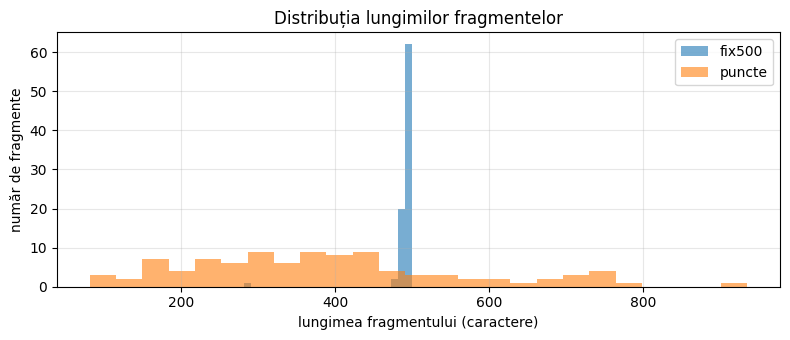

In [5]:
BODY_END = anexa                                     # anexa (tabelul gol de notare) nu intră în index

def points_in(start, end, min_overlap=50):
    res = []
    for n, (s, e) in spans.items():
        ov = min(end, e) - max(start, s)
        if ov >= min(min_overlap, e - s): res.append(n)
    return res

def mk_chunk(cid, start, end, text):
    return {"id": cid, "text": text, "start": start, "end": end, "page": page_of(start),
            "pages": sorted({page_of(start), page_of(end - 1)}), "points": points_in(start, end)}

def chunks_fixed(size=500, overlap=100):
    out, start = [], 0
    while start < BODY_END:
        end = min(start + size, BODY_END)
        if end < BODY_END:                             # mut capătul la un spațiu
            sp = full_text.rfind(" ", start + size // 2, end)
            end = sp if sp > 0 else end
        out.append(mk_chunk(f"fix{size}_{len(out)}", start, end, norm_ws(full_text[start:end])))
        if end >= BODY_END: break
        nxt = end - overlap
        sp = full_text.find(" ", nxt)
        start = sp + 1 if 0 <= sp < end else nxt
    return out

def chunks_struct(max_len=900):
    out = []
    for n, (s, e) in spans.items():
        head = heading_at(s)
        body = full_text[s:e]
        # bucăți de cel mult max_len caractere, tăiate la sfârșit de propoziție
        parts, cur = [], 0
        while len(body) - cur > max_len:
            cut = body.rfind(". ", cur, cur + max_len)
            cut = cut + 1 if cut > cur else cur + max_len
            parts.append((cur, cut)); cur = cut
        parts.append((cur, len(body)))
        for a, b in parts:
            out.append(mk_chunk(f"pct{n}_{a}", s + a, s + b, f"[{head}] " + norm_ws(body[a:b])))
            out[-1]["points"] = [n]
    return out

CHUNKS = {"fix500": chunks_fixed(500, 100), "puncte": chunks_struct()}
for name, ch in CHUNKS.items():
    L = [len(c["text"]) for c in ch]
    print(f"{name:7s}: {len(ch):3d} fragmente | lungime medie {np.mean(L):.0f} car. (min {min(L)}, max {max(L)})")
print("\nExemplu (fix500):", CHUNKS["fix500"][40]["text"][:300], "...", "| puncte:", CHUNKS["fix500"][40]["points"])
print("\nExemplu (puncte):", CHUNKS["puncte"][75]["text"][:300], "| pagini:", CHUNKS["puncte"][75]["pages"])

plt.figure(figsize=(8, 3.5))
for name, ch in CHUNKS.items():
    plt.hist([len(c["text"]) for c in ch], bins=25, alpha=0.6, label=name)
plt.xlabel("lungimea fragmentului (caractere)"); plt.ylabel("număr de fragmente")
plt.title("Distribuția lungimilor fragmentelor"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 3. Indexarea

**Indexul lexical — BM25.** Notează un fragment după cuvintele comune cu întrebarea:

- un cuvânt rar în document (de exemplu „contestație”) contează mai mult decât unul frecvent („master”);
- repetarea unui cuvânt aduce tot mai puțin, adică are efect de saturație;
- fragmentele lungi sunt penalizate.

Tokenizarea:

- litere mici și **fără diacritice**, pentru că oamenii scriu des „si” în loc de „și”;
- elimin cuvintele de legătură (stopwords), de exemplu „de”, „la”, „și”;
- **trunchiez fiecare cuvânt la 6 litere.** E o lematizare foarte simplă, dar româna are multe forme pentru același cuvânt: „credite / creditelor / creditul” devin toate „credit”, iar „susținerea / susține / susținut” devin „sustin”.

**Indexul dens — embeddings.** Fiecare fragment devine un vector de 384 de numere, produs de modelul `multilingual-e5-small`. Vectorii sunt normalizați, deci **similaritatea cosinus** e un simplu produs scalar.

- **Avantaj:** textele cu același sens ajung aproape, chiar fără cuvinte comune („pauză de la studii” ≈ „întreruperea studiilor”).
- **Particularitate E5:** întrebările primesc prefixul `query: `, iar fragmentele `passage: `, așa cum a fost antrenat modelul.

Vectorii se salvează în `artifacts/`, ca să nu-i recalculez.

In [6]:
STOP = set('''a ai al ale alt am ar are as asa au ca cand care cat ce cea cei cel cele ci cu da daca de din dintre
du e ea el este eu fi fie fost i ia iar il in la le li lor lui ma mai mi ne ni nici nu o pe pentru prin sa sau
se si sunt te tot toti un una unei unui unor va vor cum cine unde poate pot fac face cu care catre fara dupa'''.split())

def strip_diacritics(t):
    return "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")

def tokenize(t, stem=6):
    toks = re.findall(r"[a-z0-9]+(?:[.,][0-9]+)?", strip_diacritics(t.lower()))
    return [w[:stem] for w in toks if w not in STOP]

print("Exemplu de tokenizare:", tokenize("Câte credite de studii transferabile ECTS au studiile de master, cu media 9,01?"))

emb_model = SentenceTransformer(EMB_NAME, device=device)
INDEX = {}
for name, ch in CHUNKS.items():
    t0 = time.perf_counter()
    bm25 = BM25Okapi([tokenize(c["text"]) for c in ch])
    path = f"artifacts/emb_{name}.npy"
    E = emb_model.encode(["passage: " + c["text"] for c in ch], normalize_embeddings=True, batch_size=32)
    np.save(path, E)
    INDEX[name] = {"bm25": bm25, "emb": E}
    print(f"{name:7s}: BM25 + {E.shape[0]} vectori × {E.shape[1]} dimensiuni în {time.perf_counter() - t0:.1f} s → {path}")

Exemplu de tokenizare: ['cate', 'credit', 'studii', 'transf', 'ects', 'studii', 'master', 'media', '9,01']


fix500 : BM25 + 85 vectori × 384 dimensiuni în 1.7 s → artifacts/emb_fix500.npy
puncte : BM25 + 96 vectori × 384 dimensiuni în 0.3 s → artifacts/emb_puncte.npy


## 4. Căutarea — patru variante

1. **BM25:** doar potrivirea de cuvinte.
2. **Dens:** doar similaritatea cosinus a embeddings-urilor.
3. **Hibrid cu RRF** (*Reciprocal Rank Fusion*): combin cele două clasamente, cu scorul $\text{RRF}(d) = \sum_{m \in \{\text{BM25}, \text{dens}\}} \frac{1}{k + \text{rang}_m(d)}$ și $k = 60$. Folosesc **rangul**, nu scorul brut, pentru că scorurile BM25 (de exemplu 12,7) și cele cosinus (0,83) au scări diferite și nu se pot aduna direct. Un fragment aflat sus în ambele liste câștigă.
4. **Hibrid + reranker:** primele 20 de fragmente din RRF sunt notate din nou de un **cross-encoder**.
   - **Bi-encoder** (căutarea densă): întrebarea și fragmentul sunt codate **separat**, deci fragmentele se pot pre-calcula. E rapid, dar întrebarea și fragmentul nu se „văd” unul pe altul.
   - **Cross-encoder:** primește **perechea** (întrebare, fragment) în același transformer, cu atenție între ele. E mult mai precis, dar trebuie rulat pentru fiecare pereche. De aceea îl aplic doar pe cei 20 de candidați.

In [7]:
reranker = CrossEncoder(RERANK_NAME, device=device)
TOP_CAND = 20

def search(query, name, method, k=5):
    ch, idx = CHUNKS[name], INDEX[name]
    if method == "BM25":
        order = np.argsort(-idx["bm25"].get_scores(tokenize(query)))
    elif method == "Dens":
        q = emb_model.encode(["query: " + query], normalize_embeddings=True)[0]
        order = np.argsort(-(idx["emb"] @ q))
    else:
        r_bm = np.argsort(-idx["bm25"].get_scores(tokenize(query)))
        q = emb_model.encode(["query: " + query], normalize_embeddings=True)[0]
        r_de = np.argsort(-(idx["emb"] @ q))
        rrf = np.zeros(len(ch))
        for ranking in (r_bm, r_de):
            rrf[ranking] += 1.0 / (60 + np.arange(1, len(ch) + 1))
        order = np.argsort(-rrf)
        if method == "Hibrid + reranker":
            cand = order[:TOP_CAND]
            scores = reranker.predict([(query, ch[i]["text"]) for i in cand])
            order = np.concatenate([cand[np.argsort(-scores)], order[TOP_CAND:]])
    return [ch[i] for i in order[:k]]

METHODS = ["BM25", "Dens", "Hibrid RRF", "Hibrid + reranker"]
demo_q = "Pot să iau o pauză de la studii la master?"
print("Întrebare:", demo_q, "\n")
for m in METHODS:
    print(f"— {m}")
    for c in search(demo_q, "puncte", m, k=3):
        print(f"   p. {c['page']:2d} | pct. {c['points']} | {c['text'][:110]}...")

Întrebare: Pot să iau o pauză de la studii la master? 

— BM25
   p.  9 | pct. [65] | [III. Organizarea studiilor superioare de master] 65. Studiile superioare de master se finalizează cu susținer...
   p.  8 | pct. [53] | [III. Organizarea studiilor superioare de master] 53. Pe parcursul studiilor superioare de master, studenții p...
   p.  5 | pct. [27] | [II. Admiterea la studiile superioare de master] 27. Candidații care au absolvit un program de master sau un p...
— Dens
   p.  8 | pct. [55] | [III. Organizarea studiilor superioare de master] 55. Studentul poate întrerupe studiile superioare de master,...
   p.  4 | pct. [24] | [II. Admiterea la studiile superioare de master] 24. Candidații au dreptul de a se înscrie la concursul de adm...
   p.  8 | pct. [53] | [III. Organizarea studiilor superioare de master] 53. Pe parcursul studiilor superioare de master, studenții p...
— Hibrid RRF
   p.  8 | pct. [53] | [III. Organizarea studiilor superioare de master] 53. Pe parcursul studi

## 5. Setul de evaluare

Am scris **20 de întrebări** după ce am citit tot regulamentul. Fiecare are:

- **răspunsul de referință**;
- **punctele sursă**, din care rezultă paginile;
- **faptele-cheie** (cifre, termeni) după care verific automat dacă răspunsul generat le conține.

Întrebările sunt de trei tipuri:

- **exact** (11): conțin termenii sau cifrele din text („Câte credite ECTS…”, „calificativul B”). Aici mă aștept ca BM25 să fie bun.
- **parafrază** (7): formulate cum ar întreba un student, cu alte cuvinte decât regulamentul („Pot să iau o pauză de la studii?” față de textul „Studentul poate întrerupe studiile…”). Aici căutarea densă ar trebui să câștige.
- **fără răspuns** (2): informația nu e în regulament (taxa de studii, căminul). Sistemul trebuie să răspundă „Nu am găsit în documente”. Pe acestea nu le includ în metricile de căutare.

In [8]:
Q = [
 dict(id="q01", tip="exact", q="Câte credite de studii transferabile ECTS corespund studiilor superioare de master?",
      ref="90–120 de credite ECTS, câte 30 pentru fiecare semestru.", puncte=[39], cheie=[["90"], ["120"]]),
 dict(id="q02", tip="exact", q="Câte ore academice se alocă pentru un credit de studiu la master?",
      ref="Un credit se alocă pentru 30 de ore academice.", puncte=[39], cheie=[["30"]]),
 dict(id="q03", tip="exact", q="Ce medie generală la licență permite înmatricularea în afara concursului la master?",
      ref="Media generală de minimum 9,01 (A), în cadrul aceluiași domeniu, în limita locurilor din Comanda de stat.",
      puncte=[25], cheie=[["9,01"]]),
 dict(id="q04", tip="parafrază", q="Am terminat licența în alt domeniu. Ce trebuie să fac ca să fiu primit la un master din alt domeniu?",
      ref="Trebuie să acumuleze 30 de credite ECTS la disciplinele fundamentale și de specialitate (minimul curricular inițial).",
      puncte=[30, 31, 32], cheie=[["30"]]),
 dict(id="q05", tip="parafrază", q="Pot să iau o pauză de la studii la master? Pentru cât timp?",
      ref="Da, studiile se pot întrerupe pe motive întemeiate pentru cel mult un an academic.", puncte=[55],
      cheie=[["un an", "1 an"]]),
 dict(id="q06", tip="exact", q="Ce medie academică este necesară pentru a participa la un program de mobilitate academică?",
      ref="Media în sesiuni de cel puțin 8,5 la profilul umanist și 7,5 la profilul real.", puncte=[57],
      cheie=[["8,5"], ["7,5"]]),
 dict(id="q07", tip="exact", q="Din câte persoane este formată comisia de evaluare a tezelor de master?",
      ref="Din cinci persoane: președinte, vicepreședinte și 3 membri; secretarul nu are drept de vot.",
      puncte=[82, 83], cheie=[["cinci", "5"]]),
 dict(id="q08", tip="parafrază", q="Poate un profesor de la USM să fie președintele comisiei la susținerea tezei de master?",
      ref="Nu. Președintele este un specialist care nu activează în USM, numit cel mult doi ani consecutiv.",
      puncte=[84], cheie=[["nu activeaz", "nu poate", "din afara", "care nu"]]),
 dict(id="q09", tip="exact", q="Cum se calculează media generală de master?",
      ref="Media aritmetică dintre nota la susținerea tezei și media generală pe semestre, cu două zecimale.",
      puncte=[89], cheie=[["teza", "tezei"], ["semestr"]]),
 dict(id="q10", tip="exact", q="În ce termen se poate depune o contestație la evaluarea tezei de master?",
      ref="În maximum o zi lucrătoare de la afișarea rezultatelor; contestația privește doar procedura și se rezolvă în două zile lucrătoare.",
      puncte=[90], cheie=[["o zi", "1 zi", "24"]]),
 dict(id="q11", tip="parafrază", q="Ce se întâmplă dacă pic susținerea tezei de master?",
      ref="Poate susține repetat de cel mult două ori în trei ani, cu plată; după a treia încercare nereușită primește un certificat de absolvire.",
      puncte=[91, 92], cheie=[["doua ori", "2 ori"]]),
 dict(id="q12", tip="exact", q="Cu cât timp înainte de susținere mai poate fi schimbată tema tezei de master?",
      ref="Cel târziu cu 3 luni înainte de susținere.", puncte=[76], cheie=[["3 luni", "trei luni"]]),
 dict(id="q13", tip="exact", q="Ce tipuri de diplome de master se eliberează?",
      ref="MS pentru masterul științific și MP pentru masterul profesional.", puncte=[67], cheie=[["ms"], ["mp"]]),
 dict(id="q14", tip="exact", q="Ce pondere din credite revine stagiilor de practică la master?",
      ref="8–12% din credite.", puncte=[50], cheie=[["8"], ["12"]]),
 dict(id="q15", tip="parafrază", q="Lucrez deja în domeniu. Pot primi credite pentru experiența mea de muncă?",
      ref="Da, cu experiență dovedită de cel puțin 1 an în domeniu și dacă lucrează în continuare; creditele se atribuie după evaluarea competențelor.",
      puncte=[51], cheie=[["1 an", "un an"]]),
 dict(id="q16", tip="parafrază", q="Pot face masterul fără să merg zilnic la cursuri, de exemplu la distanță?",
      ref="Da, la frecvență redusă sau la distanță: doar cu taxă și cu un semestru în plus; la Psihologie și Studiul limbilor doar cu frecvență.",
      puncte=[41, 43, 44, 45, 54], cheie=[["distan"], ["tax", "semestr"]]),
 dict(id="q17", tip="parafrază", q="Pot să-mi scriu teza de master în engleză?",
      ref="Da, într-o limbă de circulație internațională, însoțită de un rezumat de 1 pagină în română.",
      puncte=[78, 79], cheie=[["rezumat"]]),
 dict(id="q18", tip="exact", q="Ce notă corespunde calificativului B din scala ECTS?",
      ref="8,01–9,00.", puncte=[88], cheie=[["8,01"]]),
 dict(id="q19", tip="fără răspuns", q="Cât costă taxa de studii la master la USM?",
      ref="Regulamentul nu precizează suma (spune doar că taxele sunt anunțate în oferta educațională).", puncte=[], cheie=[]),
 dict(id="q20", tip="fără răspuns", q="Cum pot obține un loc în cămin în timpul masterului?",
      ref="Nu este în regulament.", puncte=[], cheie=[]),
]
for x in Q:
    x["pagini"] = sorted({p for n in x["puncte"] for p in POINT_PAGES[n]})
QA = [x for x in Q if x["puncte"]]                     # întrebările cu răspuns (pentru căutare)
pd.DataFrame(Q)[["id", "tip", "q", "puncte", "pagini"]]

,id,tip,q,puncte,pagini
0,q01,exact,Câte credite de studii transferabile ECTS core...,[39],[6]
1,q02,exact,Câte ore academice se alocă pentru un credit d...,[39],[6]
2,q03,exact,Ce medie generală la licență permite înmatricu...,[25],"[4, 5]"
3,q04,parafrază,Am terminat licența în alt domeniu. Ce trebuie...,"[30, 31, 32]","[5, 6]"
4,q05,parafrază,Pot să iau o pauză de la studii la master? Pen...,[55],[8]
5,q06,exact,Ce medie academică este necesară pentru a part...,[57],[8]
6,q07,exact,Din câte persoane este formată comisia de eval...,"[82, 83]",[11]
7,q08,parafrază,Poate un profesor de la USM să fie președintel...,[84],[11]
8,q09,exact,Cum se calculează media generală de master?,[89],[12]
9,q10,exact,În ce termen se poate depune o contestație la ...,[90],[12]


## 6. Evaluarea căutării

**Metrici** (calculate pe cele 18 întrebări cu răspuns):

- **Hit@k:** procentul de întrebări la care **cel puțin un** fragment relevant e printre primele $k$. Hit@3 și Hit@5 contează cel mai mult, pentru că generatorul primește primele 3–5 fragmente.
- **MRR** (*Mean Reciprocal Rank*): media lui $1/\text{rang}$ al primului fragment relevant (1 dacă e primul, 0,5 dacă e al doilea, …, 0 dacă nu apare în primele 20). Măsoară **cât de sus** e răspunsul, nu doar dacă apare.

Un fragment e relevant dacă conține cel puțin unul dintre punctele sursă ale întrebării.

In [9]:
def eval_retrieval(name, method, questions=QA, kmax=20):
    rows = []
    for x in questions:
        res = search(x["q"], name, method, k=kmax)
        rel = [bool(set(c["points"]) & set(x["puncte"])) for c in res]
        rank = rel.index(True) + 1 if any(rel) else None
        rows.append({"id": x["id"], "tip": x["tip"], "rang": rank,
                     **{f"Hit@{k}": rank is not None and rank <= k for k in (1, 3, 5)},
                     "RR": 1 / rank if rank else 0.0})
    return pd.DataFrame(rows)

t0 = time.perf_counter()
DET, summary = {}, []
for name in CHUNKS:
    for m in METHODS:
        d = eval_retrieval(name, m); DET[(name, m)] = d
        summary.append({"fragmentare": name, "metodă": m, "Hit@1": d["Hit@1"].mean(), "Hit@3": d["Hit@3"].mean(),
                        "Hit@5": d["Hit@5"].mean(), "MRR": d["RR"].mean()})
res_ret = pd.DataFrame(summary)
print(f"Evaluare în {time.perf_counter() - t0:.1f} s")
res_ret.to_csv("artifacts/rezultate_cautare.csv", index=False)
res_ret.style.format({c: "{:.3f}" for c in ["Hit@1", "Hit@3", "Hit@5", "MRR"]}).background_gradient(cmap="Greens", subset=["Hit@1", "Hit@3", "Hit@5", "MRR"])

Evaluare în 6.1 s


,fragmentare,metodă,Hit@1,Hit@3,Hit@5,MRR
0,fix500,BM25,0.778,0.944,1.000,0.854
1,fix500,Dens,0.778,1.000,1.000,0.861
2,fix500,Hibrid RRF,0.889,1.000,1.000,0.935
3,fix500,Hibrid + reranker,0.889,1.000,1.000,0.935
4,puncte,BM25,0.778,0.889,0.944,0.838
5,puncte,Dens,0.778,0.944,1.000,0.856
6,puncte,Hibrid RRF,0.833,0.944,0.944,0.894
7,puncte,Hibrid + reranker,1.000,1.000,1.000,1.000


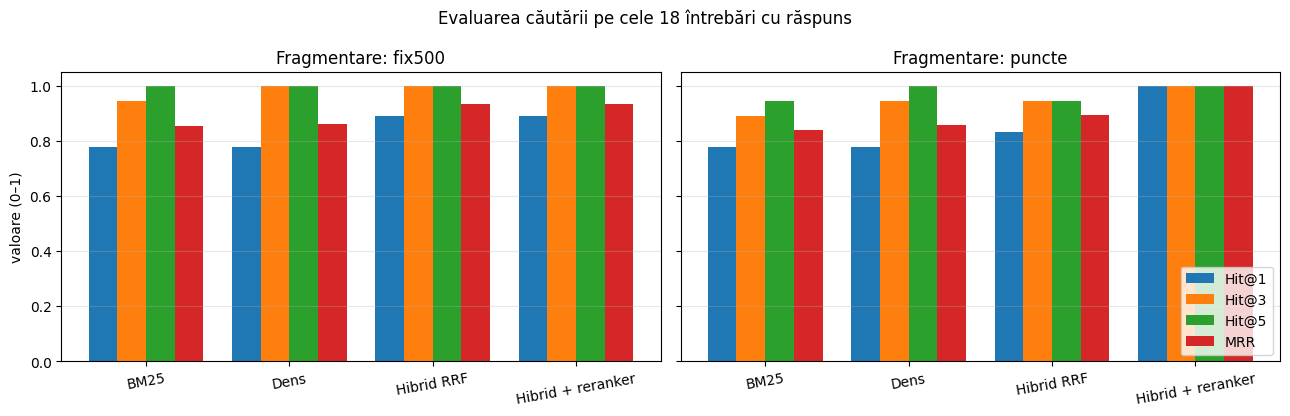

,MRR exact,MRR parafrază
fix500 | BM25,1.000,0.624
fix500 | Dens,0.833,0.905
fix500 | Hibrid RRF,0.955,0.905
fix500 | Hibrid + reranker,0.939,0.929
puncte | BM25,1.000,0.583
puncte | Dens,0.955,0.702
puncte | Hibrid RRF,0.955,0.798
puncte | Hibrid + reranker,1.000,1.000


Cea mai bună combinație (după MRR): puncte + Hibrid + reranker (MRR = 1.000, Hit@3 = 1.000)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, name in zip(axes, CHUNKS):
    sub = res_ret[res_ret.fragmentare == name]
    x = np.arange(len(METHODS)); w = 0.2
    for j, met in enumerate(["Hit@1", "Hit@3", "Hit@5", "MRR"]):
        ax.bar(x + (j - 1.5) * w, sub[met], w, label=met)
    ax.set_xticks(x); ax.set_xticklabels(METHODS, rotation=10); ax.set_ylim(0, 1.05)
    ax.set_title(f"Fragmentare: {name}"); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("valoare (0–1)"); axes[1].legend(loc="lower right")
fig.suptitle("Evaluarea căutării pe cele 18 întrebări cu răspuns"); plt.tight_layout(); plt.show()

# pe tipuri de întrebări: exact vs. parafrază (MRR)
by_type = pd.DataFrame({f"{n} | {m}": DET[(n, m)].groupby("tip")["RR"].mean() for n in CHUNKS for m in METHODS}).T
by_type.columns = [f"MRR {c}" for c in by_type.columns]
display(by_type.round(3))

BEST = res_ret.sort_values(["MRR", "Hit@3"], ascending=False).iloc[0]
BEST_CHUNK, BEST_METHOD = BEST["fragmentare"], BEST["metodă"]
print(f"Cea mai bună combinație (după MRR): {BEST_CHUNK} + {BEST_METHOD} (MRR = {BEST['MRR']:.3f}, Hit@3 = {BEST['Hit@3']:.3f})")

In [11]:
# unde greșește cea mai bună variantă: rangul primului fragment relevant pentru fiecare întrebare
ranks = pd.DataFrame({f"{n} | {m}": DET[(n, m)].set_index("id")["rang"] for n in CHUNKS for m in METHODS})
ranks.insert(0, "tip", DET[(BEST_CHUNK, BEST_METHOD)].set_index("id")["tip"])
ranks.fillna(">20")

,tip,fix500 | BM25,fix500 | Dens,fix500 | Hibrid RRF,fix500 | Hibrid + reranker,puncte | BM25,puncte | Dens,puncte | Hibrid RRF,puncte | Hibrid + reranker
id,,,,,,,,,
q01,exact,1,1,1,1,1.0,1,1,1
q02,exact,1,1,1,1,1.0,1,1,1
q03,exact,1,1,1,1,1.0,1,1,1
q04,parafrază,3,1,1,2,4.0,3,2,1
q05,parafrază,2,1,1,1,>20,3,12,1
q06,exact,1,3,2,1,1.0,2,2,1
q07,exact,1,1,1,1,1.0,1,1,1
q08,parafrază,1,1,1,1,1.0,1,1,1
q09,exact,1,1,1,1,1.0,1,1,1


**Interpretare:**

- **BM25 e perfect la întrebările „exacte”** (MRR 1,000 la ambele fragmentări): cifrele și termenii din întrebare („ECTS”, „calificativul B”, „contestație”) apar exact așa în text. **La parafraze e slab:** MRR 0,58–0,62. Exemplul tipic e q05, „Pot să iau o **pauză** de la studii?”: regulamentul spune „poate **întrerupe** studiile”, iar BM25 pe fragmentele pe puncte nu găsește punctul 55 nici în primele 20.
- **Căutarea densă face invers.** La parafraze e mult mai bună: pe fragmentele fixe, MRR 0,905 față de 0,624. Pe q05 o pune pe locul 3 la fragmentele pe puncte și pe locul 1 la cele fixe. Dar la întrebările exacte pierde uneori ordinea fină: la q06, de exemplu, e pe locul 2–3 în loc de 1.
- **RRF** combină cele două liste și e mai stabil decât fiecare metodă singură: MRR 0,935 pe fragmentele fixe. Totuși, poate și să strice. Pe q05 cu fragmentele pe puncte, BM25 n-a găsit deloc punctul 55, iar RRF l-a coborât pe locul 12, deși căutarea densă îl avea pe locul 3.
- **Reranker-ul (cross-encoder) a corectat toate aceste cazuri.** Pe fragmentele pe puncte, primul fragment e relevant la **toate cele 18 întrebări**: Hit@1 = 1,000, MRR = 1,000. Diferența vine din faptul că cross-encoder-ul citește întrebarea și fragmentul **împreună**. Așa a legat „pauză” de „întrerupe”, chiar când primise punctul 55 de pe locul 12.
- **Fragmentarea.** Fragmentele pe puncte câștigă doar împreună cu reranker-ul. Cu BM25 sau cu căutarea densă singure, fragmentele fixe de 500 de caractere au fost chiar puțin mai bune (MRR 0,854 față de 0,838 la BM25, 0,861 față de 0,856 la dens). Un fragment fix conține de obicei 2–3 puncte vecine, deci are mai multe șanse să „atingă” punctul căutat. Un punct izolat e mai precis, dar trebuie găsit exact.
- **Limita evaluării:** sunt doar 18 întrebări, deci o întrebare înseamnă 0,056 la Hit@k. Diferențele de 1–2 întrebări (de exemplu 0,935 față de 0,894) nu sunt concludente. Clar și consecvent e doar câștigul reranker-ului.

## 7. Generarea

**Promptul** îi cere modelului:

- să răspundă **doar** din fragmentele primite;
- să citeze pagina ca `[p. N]`;
- să spună exact „Nu am găsit în documente.” dacă informația lipsește.

Fragmentele sunt numerotate și au pagina în față, ca modelul să știe ce să citeze.

**Setările:**

- **Contextul:** primele $k = 3$ fragmente din cea mai bună combinație de căutare de la secțiunea 6.
- **Decodarea:** lacomă (*greedy*, `do_sample=False`), deci răspunsurile sunt reproductibile, iar modelul nu „improvizează”.

Funcția `rag(question)` întoarce răspunsul, sursele (paginile citate) și fragmentele folosite.

In [12]:
t0 = time.perf_counter()
tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm_dtype = torch.float16 if device in ("cuda", "mps") else torch.float32
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=llm_dtype).to(device).eval()
print(f"{LLM_NAME}: {sum(p.numel() for p in llm.parameters())/1e9:.2f} mld. parametri, încărcat în {time.perf_counter() - t0:.0f} s")

SYSTEM_RAG = ("Ești un asistent care răspunde la întrebări despre Regulamentul USM privind studiile superioare de master. "
              "Răspunde în limba română, scurt (1–3 propoziții), folosind DOAR informațiile din fragmentele primite. "
              "După fiecare afirmație citează pagina sursă în formatul [p. N]. "
              "Dacă fragmentele nu conțin răspunsul, scrie exact: „Nu am găsit în documente.” și nimic altceva.")
SYSTEM_NORAG = ("Ești un asistent care răspunde la întrebări despre regulamentul studiilor de master de la "
                "Universitatea de Stat din Moldova (USM). Răspunde în limba română, scurt (1–3 propoziții).")

@torch.no_grad()
def generate(system, user, max_new_tokens=200):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    enc = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def fmt_pages(c):
    return f"p. {c['pages'][0]}" if len(c["pages"]) == 1 else f"p. {c['pages'][0]}–{c['pages'][-1]}"

def rag(question, k=3, name=None, method=None):
    ctx = search(question, name or BEST_CHUNK, method or BEST_METHOD, k=k)
    context = "\n\n".join(f"Fragmentul {i+1} [{fmt_pages(c)}]:\n{c['text']}" for i, c in enumerate(ctx))
    user = f"Fragmente din regulament:\n\n{context}\n\nÎntrebare: {question}"
    answer = generate(SYSTEM_RAG, user)
    cited = sorted({int(p) for p in re.findall(r"p\.\s*(\d+)", answer)})
    return {"answer": answer, "sources": cited, "contexts": ctx}

def no_rag(question):
    return generate(SYSTEM_NORAG, question)

Qwen/Qwen2.5-3B-Instruct: 3.09 mld. parametri, încărcat în 106 s


In [13]:
DEMO = ["q01", "q05", "q10", "q15", "q17", "q19"]
QD = {x["id"]: x for x in Q}
t0 = time.perf_counter()
for qid in DEMO:
    x = QD[qid]; r = rag(x["q"])
    print(f"■ {qid} ({x['tip']}): {x['q']}")
    print(f"  RAG:        {r['answer']}")
    print(f"  surse:      pagini citate {r['sources']} | fragmente: " + ", ".join(f"{fmt_pages(c)} pct.{c['points']}" for c in r["contexts"]))
    print(f"  fără RAG:   {no_rag(x['q'])}")
    print(f"  referință:  {x['ref']} (pct. {x['puncte']}, p. {x['pagini']})\n")
print(f"Timp: {time.perf_counter() - t0:.0f} s pentru {len(DEMO)} întrebări × 2 generări")

■ q01 (exact): Câte credite de studii transferabile ECTS corespund studiilor superioare de master?
  RAG:        90-120 de credite de studii transferabile ECTS [p. 6].
  surse:      pagini citate [6] | fragmente: p. 6 pct.[39], p. 6 pct.[40], p. 5 pct.[30]
  fără RAG:   Studii superioare de master au 240 credite ECTS.
  referință:  90–120 de credite ECTS, câte 30 pentru fiecare semestru. (pct. [39], p. [6])

■ q05 (parafrază): Pot să iau o pauză de la studii la master? Pentru cât timp?
  RAG:        Pot să iau o pauză de la studii la master pentru o perioadă de cel mult un an academic. [p. 8]
  surse:      pagini citate [8] | fragmente: p. 8 pct.[55], p. 10 pct.[76], p. 3 pct.[11]
  fără RAG:   Pentru a putea lua o pauză, trebuie să respecti regulile specifice universității USM. General, este de 2-3 luni.
  referință:  Da, studiile se pot întrerupe pe motive întemeiate pentru cel mult un an academic. (pct. [55], p. [8])

■ q10 (exact): În ce termen se poate depune o contestație la eval

**Comparația RAG / fără RAG** (Qwen2.5-3B, aceleași 6 întrebări):

| Întrebare | Fără RAG | Cu RAG | Referință |
|---|---|---|---|
| q01: credite ECTS | „240 credite ECTS” ❌ | „90–120 … [p. 6]” ✅ | 90–120 |
| q05: pauză | „în general 2–3 luni” ❌ | „cel mult un an academic [p. 8]” ✅ | cel mult un an |
| q10: contestație | „10 zile” ❌ | „maximum o zi lucrătoare … [p. 12]” ✅ | o zi lucrătoare |
| q15: experiență de muncă | „doar studenților, nu profesioniștilor” ❌ | „da, cu cel puțin un an de experiență … [p. 7–8]” ✅ (incomplet) | da, cu ≥ 1 an |
| q17: teza în engleză | „Da, putem începe cu planificarea tezei” ❌, nu a înțeles întrebarea | „Nu am găsit în documente” ❌, refuz greșit | da, cu rezumat în română |
| q19: taxa de studii | „între 500 și 2000 euro anual” ❌, inventat | „Nu am găsit în documente” ✅ | nu e în regulament |

- **Fără documente**, modelul a **inventat la toate cele 6 întrebări** un răspuns sigur pe el, dar greșit: cifre plauzibile (240 de credite, 10 zile, 500–2000 de euro), fără nicio sursă. E exact problema de halucinație pe care o rezolvă RAG.
- **Cu RAG** a dat răspunsul corect, cu pagina citată, la 4 din 6. La q15 răspunsul e incomplet, vezi secțiunea 8. A refuzat corect întrebarea fără răspuns (q19). A refuzat greșit q17: fragmentul cu răspunsul era chiar primul în context, dar modelul nu a făcut legătura dintre „engleză” și „limbă de circulație internațională”.

## 8. Evaluarea răspunsurilor

Rulez sistemul pe toate cele 20 de întrebări. Mai întâi calculez trei verificări **automate**:

- **Fapt-cheie:** răspunsul conține cifrele sau termenii din referință? Compar fără diacritice și fără să țin cont de majuscule.
- **Citare corectă:** cel puțin o pagină citată e o pagină a punctului sursă.
- **Refuz:** la întrebările fără răspuns, modelul a spus „Nu am găsit în documente”? La cele cu răspuns, refuzul e o greșeală.

Verificările automate sunt doar un indiciu: un răspuns poate conține „30” și totuși să fie greșit. De aceea, după rulare, citesc fiecare răspuns și îl notez manual: **corect / parțial / greșit** și **fidel contextului** (da/nu).

In [14]:
def n_(t):
    return strip_diacritics(t.lower()).replace(",", ".")

def auto_eval(x, r):
    refuz = "nu am gasit" in n_(r["answer"])
    fapt = all(any(n_(a) in n_(r["answer"]) for a in grup) for grup in x["cheie"]) if x["cheie"] else None
    cit = bool(set(r["sources"]) & set(x["pagini"])) if x["pagini"] else None
    return {"fapt_cheie": fapt, "citare_corecta": cit, "refuz": refuz}

def run_all(k=3, name=None, method=None):
    rows = []
    for x in Q:
        r = rag(x["q"], k=k, name=name, method=method)
        rows.append({"id": x["id"], "tip": x["tip"], "întrebare": x["q"], "răspuns": r["answer"],
                     "pagini citate": r["sources"], "pagini referință": x["pagini"], **auto_eval(x, r)})
    return pd.DataFrame(rows)

def scor(df):
    ans, una = df[df.tip != "fără răspuns"], df[df.tip == "fără răspuns"]
    return {"fapt-cheie (din 18)": int(ans.fapt_cheie.sum()), "citare corectă (din 18)": int(ans.citare_corecta.sum()),
            "refuzuri greșite (din 18)": int(ans.refuz.sum()), "refuzuri corecte (din 2)": int(una.refuz.sum())}

t0 = time.perf_counter()
RES = run_all(k=3)
RES.to_csv("artifacts/raspunsuri_k3.csv", index=False)
print(f"Timp: {time.perf_counter() - t0:.0f} s | {scor(RES)}")
pd.set_option("display.max_colwidth", 400)
RES[["id", "tip", "răspuns", "pagini citate", "pagini referință", "fapt_cheie", "citare_corecta", "refuz"]]

Timp: 62 s | {'fapt-cheie (din 18)': 14, 'citare corectă (din 18)': 17, 'refuzuri greșite (din 18)': 2, 'refuzuri corecte (din 2)': 2}


,id,tip,răspuns,pagini citate,pagini referință,fapt_cheie,citare_corecta,refuz
0,q01,exact,90-120 de credite de studii transferabile ECTS [p. 6].,[6],[6],True,True,False
1,q02,exact,Un credit de studiu la master se alocă 30 de ore academice. [p. 6],[6],[6],True,True,False
2,q03,exact,"Medie generală de minim 9,01 (A) la licență permite înmatricularea în afara concursului la programuri de master. [p. 4–5]",[4],"[4, 5]",True,True,False
3,q04,parafrază,"Pentru a fi acceptat la un master în alt domeniu după licență, trebuie să acumulezi minimul curricular inițial necesar, de asemenea ca și în perioada studiilor de licență, prin diverse modalități precum transferul creditelor sau prin cursuri opționale. [p. 5]",[5],"[5, 6]",False,True,False
4,q05,parafrază,Pot să iau o pauză de la studii la master pentru o perioadă de cel mult un an academic. [p. 8],[8],[8],True,True,False
5,q06,exact,"Studentul trebuie să are media academică în sesiuni nu mai puțin de „8,5” pentru profilul umanist și „7,5” pentru profilul real pentru a putea participa la un program de mobilitate academică [p. 8].",[8],[8],True,True,False
6,q07,exact,Comisia de evaluare a tezei de master este formată din 5 persoane [p. 11].,[11],[11],True,True,False
7,q08,parafrază,Nu am găsit în documente. [p. 11],[11],[11],False,True,True
8,q09,exact,"Media generală de master se stabilește ca media aritmetică a notei obținute la susținerea tezei de master și a mediei generale pe semestrele de studii, și se calculează cu două zecimale (se scrie cu cifre și litere). [p. 12]",[12],[12],True,True,False
9,q10,exact,"Contestațiile se depun, în scris, la secretariatul facultății, pe numele rectorului USM, în termen de maximum o zi lucrătoare de la comunicarea /afișarea rezultatelor. [p. 12]",[12],[12],True,True,False


**Evaluarea manuală.** Am citit fiecare răspuns din tabelul de mai sus și l-am comparat cu referința și cu fragmentele primite:

| id | Notă | Fidel contextului | Citare | Comentariu |
|---|---|---|---|---|
| q01 | corect | da | ✅ p. 6 | 90–120 ECTS |
| q02 | corect | da | ✅ p. 6 | 30 de ore |
| q03 | corect | da | ✅ p. 4–5 | 9,01 (A); omite „același domeniu” |
| q04 | parțial | da | ✅ p. 5 | spune „minimul curricular inițial” și cum se acumulează, dar **omite cifra de 30 de credite** |
| q05 | corect | da | ✅ p. 8 | cel mult un an academic |
| q06 | corect | da | ✅ p. 8 | 8,5 umanist / 7,5 real |
| q07 | corect | da | ✅ p. 11 | 5 persoane |
| q08 | **greșit** | — | — | **refuz fals**: punctul 84 („care nu activează în cadrul USM”) era primul în context, dar modelul nu a dedus că răspunsul e „nu” |
| q09 | corect | da | ✅ p. 12 | aproape copiat din punctul 89 |
| q10 | corect | da | ✅ p. 12 | o zi lucrătoare |
| q11 | corect | da | ✅ p. 12 | de cel mult două ori în trei ani, cu plată; omite certificatul după a treia încercare |
| q12 | corect | da | ✅ p. 10 | 3 luni |
| q13 | corect | da | ✅ p. 9 | MS / MP |
| q14 | corect | da | ✅ p. 7 | 8–12% |
| q15 | parțial | da | ✅ p. 7–8 | condiția de 1 an e corectă, dar lipsește „continuă activitatea în domeniu”; formulare stângace („expunere practică”) |
| q16 | parțial | da | ✅ p. 6, 8 | „da, la distanță” e corect, dar pune accent pe condiția de acreditare (pct. 43) și **omite** taxa și semestrul în plus |
| q17 | **greșit** | — | — | **refuz fals**, deși punctele 78–79 erau în context |
| q18 | corect | da | ❌ „p. 1” | valoarea 8,01–9,00 e corectă, dar pagina citată e greșită (fragmentul era „p. 11–12”) |
| q19 | corect (refuz) | — | — | „Nu am găsit în documente” |
| q20 | corect (refuz) | — | — | „Nu am găsit în documente” |

**Rezumat:**

- **Întrebările cu răspuns (18):** 13 corecte (72%), 3 parțiale (17%), 2 greșite (11%).
- **Fidelitate:** toate cele 16 răspunsuri date (fără refuzuri) sunt susținute de context. **Nicio halucinație.**
- **Citarea:** pagina corectă la 15 din 16 răspunsuri date.
- **Întrebările fără răspuns:** amândouă refuzate corect.

**Ce nu prinde evaluarea automată:**

- La q08 și q17, „citare corectă” apare ✅ pentru că modelul a pus o pagină și după „Nu am găsit în documente” (de exemplu „[p. 11]”). Răspunsul e totuși greșit.
- La q19 și q20 apare la fel o pagină după refuz. Promptul cerea „nimic altceva”, iar modelul nu a respectat formatul.
- **Toate greșelile sunt refuzuri prea prudente, nu invenții.** Modelul de 3B refuză când răspunsul cere o mică deducție (q08: „profesor de la USM” față de „nu activează în USM”; q17: „engleză” față de „limbă de circulație internațională”).

## 9. Experiment: un singur parametru o dată

**9.1 Dimensiunea fragmentelor (căutare).** Păstrez metoda de căutare cea mai bună și fragmentarea de lungime fixă. Schimb doar mărimea ferestrei: 300 / 500 / 1000 de caractere, cu suprapunerea de 20% din mărime. Un fragment mic e precis, dar poate tăia răspunsul. Un fragment mare conține sigur răspunsul, dar amestecă mai multe subiecte, iar embedding-ul lui devine „media” lor.

**9.2 Numărul de fragmente $k$ trimise generatorului.** Păstrez căutarea cea mai bună și schimb doar $k$: 1 / 3 / 5. Cu $k$ mic, răspunsul poate lipsi din context. Cu $k$ mare, contextul are mai mult zgomot, iar un model mic se poate încurca.

Metoda de căutare: Hibrid + reranker (suprapunere 20%)


,mărime (car.),fragmente,Hit@1,Hit@3,Hit@5,MRR
0,300,141,0.778,0.944,1.0,0.863
1,500,85,0.889,1.000,1.0,0.935
2,1000,43,1.000,1.000,1.0,1.000


Timp experiment k: 135 s


,k,fapt-cheie (din 18),citare corectă (din 18),refuzuri greșite (din 18),refuzuri corecte (din 2)
0,1,14,18,2,2
1,3,14,17,2,2
2,5,15,17,1,0


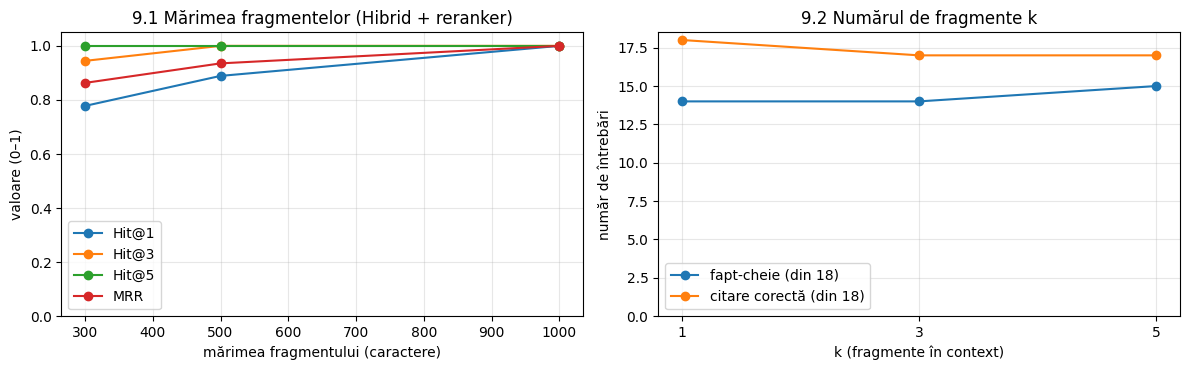

In [15]:
exp_rows = []
for size in (300, 500, 1000):
    CHUNKS[f"fix{size}"] = chunks_fixed(size, size // 5)
    ch = CHUNKS[f"fix{size}"]
    INDEX[f"fix{size}"] = {"bm25": BM25Okapi([tokenize(c["text"]) for c in ch]),
                           "emb": emb_model.encode(["passage: " + c["text"] for c in ch], normalize_embeddings=True, batch_size=32)}
    d = eval_retrieval(f"fix{size}", BEST_METHOD)
    exp_rows.append({"mărime (car.)": size, "fragmente": len(ch), "Hit@1": d["Hit@1"].mean(), "Hit@3": d["Hit@3"].mean(),
                     "Hit@5": d["Hit@5"].mean(), "MRR": d["RR"].mean()})
exp_size = pd.DataFrame(exp_rows)
print(f"Metoda de căutare: {BEST_METHOD} (suprapunere 20%)")
display(exp_size.round(3))

t0 = time.perf_counter()
exp_k = []
for k in (1, 3, 5):
    df = RES if k == 3 else run_all(k=k)
    exp_k.append({"k": k, **scor(df)})
    if k != 3: df.to_csv(f"artifacts/raspunsuri_k{k}.csv", index=False)
exp_k = pd.DataFrame(exp_k)
print(f"Timp experiment k: {time.perf_counter() - t0:.0f} s")
display(exp_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for met in ["Hit@1", "Hit@3", "Hit@5", "MRR"]:
    axes[0].plot(exp_size["mărime (car.)"], exp_size[met], "o-", label=met)
axes[0].set_xlabel("mărimea fragmentului (caractere)"); axes[0].set_ylabel("valoare (0–1)"); axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"9.1 Mărimea fragmentelor ({BEST_METHOD})"); axes[0].legend(); axes[0].grid(alpha=0.3)
for col in ["fapt-cheie (din 18)", "citare corectă (din 18)"]:
    axes[1].plot(exp_k["k"], exp_k[col], "o-", label=col)
axes[1].set_xlabel("k (fragmente în context)"); axes[1].set_ylabel("număr de întrebări"); axes[1].set_xticks([1, 3, 5])
axes[1].set_ylim(0, 18.5); axes[1].set_title("9.2 Numărul de fragmente k"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretare:**

**9.1 Mărimea fragmentelor** (fixe, cu Hibrid + reranker):
- MRR crește de la 0,863 (300 de caractere) la 0,935 (500) și 1,000 (1000). Hit@1 crește de la 0,778 la 1,000.
- La 300 de caractere, un punct lung e tăiat în 2–3 bucăți, iar bucata găsită poate fi cea fără răspuns.
- Cifrele favorizează însă fragmentele mari prin felul în care e definită metrica. Un fragment de 1000 de caractere conține 3–4 puncte, deci „atinge” punctul căutat mai ușor. Totodată îi dă generatorului de 2–3 ori mai mult text irelevant pentru fiecare fragment.
- Fragmentele pe puncte (~390 de caractere în medie) au obținut același MRR = 1,000 cu bucăți de 2,5 ori mai mici. Asta arată că **granița** fragmentului (un punct întreg) contează mai mult decât mărimea lui.

**9.2 Numărul de fragmente $k$:**

| k | fapt-cheie | citare corectă | refuzuri greșite | refuzuri corecte |
|---|---|---|---|---|
| 1 | 14 / 18 | 18 / 18 | 2 | 2 / 2 |
| 3 | 14 / 18 | 17 / 18 | 2 | 2 / 2 |
| 5 | 15 / 18 | 17 / 18 | 1 | **0 / 2** |

- **$k = 1$ ajunge aici** pentru că reranker-ul pune fragmentul corect pe primul loc la toate întrebările. Într-o colecție mai mare sau cu întrebări mai grele, $k = 1$ ar fi riscant.
- **$k = 5$** a adus un răspuns în plus cu faptul-cheie, dar **nu a mai refuzat întrebările fără răspuns**. Cu mai mult text în context, modelul găsește ceva „apropiat” (de exemplu despre taxe sau admitere) și răspunde din el, în loc să spună că lipsește informația. În acest notebook am salvat doar numerele agregate pentru $k$ = 1 și 5, nu și textul răspunsurilor. Mecanismul de mai sus e deci explicația cea mai probabilă, nu un lucru verificat răspuns cu răspuns.
- **$k = 3$ rămâne compromisul ales:** refuză corect, iar diferența de un singur fapt-cheie față de $k = 5$ nu e concludentă pe 18 întrebări.

## 10. Concluzii, limitări și noțiuni

**Ce a mers:**
- Cea mai bună căutare, fragmente pe puncte + hibrid BM25/dens + reranker, a pus fragmentul corect pe primul loc la toate cele 18 întrebări.
- Generatorul de 3B a răspuns corect la 13 din 18 și parțial la 3. Nu a inventat nimic și a citat pagina corectă la 15 din 16 răspunsuri date.
- Fără RAG, același model a inventat la toate cele 6 întrebări de test.

**Unde greșește sistemul:**
1. **Refuzuri false** (q08, q17): răspunsul era în context, dar cerea o mică deducție.
2. **Răspunsuri incomplete** (q04, q15, q16): modelul copiază o parte din punct și omite exact condiția importantă, de exemplu „30 de credite”.
3. **Formatul:** pune o pagină și după „Nu am găsit în documente”; o dată a citat „p. 1” în loc de „p. 11–12”.
4. **La $k = 5$** nu mai refuză întrebările fără răspuns.

**Ce aș îmbunătăți:**
- un generator mai mare (7B sau un model prin API), care deduce mai bine;
- **reformularea întrebării** înainte de căutare (*query rewriting*), de exemplu „engleză” → „limbă de circulație internațională”;
- un prompt cu 1–2 exemple de răspuns (*few-shot*), pentru format și pentru refuz;
- un set de evaluare mai mare, cu un LLM ca judecător pentru notarea automată, verificat prin sondaj de om;
- citarea punctului („pct. 55”), nu doar a paginii, pentru că regulamentele se citează pe puncte.

**Noțiunile folosite, pe scurt:**
- **Embedding și similaritatea cosinus:** textul devine un vector. Textele cu sens apropiat au vectori cu unghi mic între ei. Cu vectori normalizați, cosinusul e produsul scalar.
- **BM25 față de căutarea densă:** BM25 potrivește **cuvinte**. E excelent pentru cifre și termeni exacți și nu are nevoie de model, dar nu înțelege sinonimele. Căutarea densă potrivește **sensul**, dar poate rata un termen sau o cifră exactă. Datele de la secțiunea 6 arată exact acest lucru.
- **RRF:** combină clasamente, nu scoruri, pentru că scorurile metodelor au scări diferite.
- **Bi-encoder față de cross-encoder:**
  - bi-encoder: vectori calculați separat, căutare rapidă în toată colecția;
  - cross-encoder: citește perechea întrebare–fragment împreună, e precis, dar lent, deci se aplică doar pe primii 20 de candidați.
- **Hit@k și MRR:** Hit@k spune *dacă* răspunsul e în primele k fragmente. MRR spune *cât de sus* e.
- **Halucinația și fidelitatea:** halucinația e un răspuns sigur pe el, dar inventat (ca „240 de credite” fără RAG). Fidelitatea înseamnă că răspunsul se sprijină doar pe contextul primit.

## Raport

**Sistemul.** Am construit un RAG pe Regulamentul USM pentru studiile de master: 13 pagini, ~5.000 de cuvinte, 94 de puncte. Notebook-ul a rulat pe Google Colab, cu GPU T4. Pașii:

- **Ingestia:** textul extras cu PyMuPDF. `pypdf` strica diacriticele.
- **Fragmentarea:** două strategii, ferestre fixe de 500 de caractere și câte un fragment pe punct, cu titlul capitolului.
- **Indexarea:** BM25, cu tokenizare fără diacritice și cuvinte trunchiate la 6 litere, plus embeddings `multilingual-e5-small`.
- **Căutarea:** patru variante, inclusiv RRF și un reranker cross-encoder multilingv.
- **Generarea:** cu `Qwen2.5-3B-Instruct`, decodare lacomă și citarea paginii.

**Evaluarea:** un set de 20 de întrebări scrise de mine după citirea documentului. 11 folosesc termenii din text, 7 sunt parafraze, iar 2 nu au răspuns în document. Fiecare are răspunsul de referință și punctul sursă.

**Rezultatele principale:**

| Ce am măsurat | Rezultat |
|---|---|
| Cea mai bună căutare | fragmente pe puncte + hibrid + reranker: Hit@1 = 1,000, MRR = 1,000 (18 întrebări) |
| BM25, exact / parafrază | MRR 1,000 / 0,583 (pe puncte) |
| Dens, exact / parafrază | MRR 0,955 / 0,702 (pe puncte); 0,833 / 0,905 (fix 500) |
| Răspunsurile RAG (k = 3, notate manual) | 13 corecte, 3 parțiale, 2 greșite (refuzuri false) din 18; 0 halucinații; citare corectă 15/16 |
| Întrebările fără răspuns | 2/2 refuzate la k = 3; 0/2 la k = 5 |
| Fără RAG (6 întrebări) | 6/6 răspunsuri inventate sau greșite |

**Concluzii:**
- BM25 și căutarea densă se completează: una câștigă la termenii exacți, cealaltă la parafraze. Reranker-ul e componenta care a dus căutarea la 100%.
- Granița fragmentului, adică un punct întreg al regulamentului, contează mai mult decât mărimea lui.
- Generatorul mic nu inventează când are context, dar e prea prudent când răspunsul cere o deducție.
- $k = 3$ e cel mai bun compromis: la $k = 5$ modelul nu mai refuză întrebările fără răspuns.

**Limitări:**
- Doar 18 întrebări cu răspuns, deci diferențele de 1–2 întrebări nu sunt concludente.
- Un singur document.
- Notarea răspunsurilor e manuală, făcută de mine, pentru configurația $k = 3$. Pentru $k$ = 1 și 5 am doar verificările automate.
- Verificările automate (fapt-cheie, citare) sunt doar indicii: au considerat „corecte” citările de după un refuz.
- Am ales cea mai bună variantă de căutare pe același set de întrebări pe care o și evaluez. Pe întrebări noi, rezultatul ar fi probabil puțin mai slab.